 # Imports

In [1]:
# -*- coding: utf-8 -*-

import numpy as nmp
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit as fit
from scipy.interpolate import InterpolatedUnivariateSpline as ius
from netCDF4 import Dataset as ncd
import pandas as pd

from specialized_input_data.specialized_input_data import *


 # PHYSICAL PROPERTIES


 ## Global mineral fractions

In [2]:
ymas = mbulk 

ymas[0] = ymas[0] + ymas[3] + ymas[4] # Illi + Chlo + Verm
ymas[3] = 0.0
ymas[4] = 0.0

print( 'Normalization of ymas: ', nmp.sum(ymas) ) #to check that is =1

#calculate volume %
yvol = ymas/mden #densities (g cm-3)
yvol = yvol/nmp.sum(yvol)
print( 'Normalization of yvol: ', nmp.sum(yvol) )

#m are just the index in the list of minerals
hvol = yvol[mtoh] #host
fvol = yvol[mtof] #IrOx
zvol = yvol[mtoz] #Scanza 2015


Normalization of ymas:  1.0000000706
Normalization of yvol:  1.0


 ## Mineral mass densities

In [3]:
hden = mden[mtoh]
fden = mden[mtof]

dhos = nmp.average(hden, weights=hvol) 
#density of host by a weight avrg of each host mineral density
diox = iden
dhem = fden[0]
dgoe = fden[1]


 ## Scanza refractive indices

In [4]:
zrri, ziri = nmp.zeros([Hz+1,Lx]), nmp.zeros([Hz+1,Lx]) #Hz=7 Scanza host minerals(8)

for m in nmp.arange(Hz+1):

 inp = nmp.loadtxt('./scanza_mineral_data/%s.txt'%(zcri[m]))

 mwvl = inp[:,0]
 nwvl = nmp.where(mwvl[:-1]==mwvl[1:], mwvl[:-1]-1.0e-03, mwvl[:-1])
 mwvl = nmp.append(nwvl, mwvl[-1])

 mrri = inp[:,1]
 miri = inp[:,2]
 miri = nmp.where(miri<0.0, miri*(-1.0), miri)

 SpnLine = ius(mwvl, mrri, k=1, ext=3)
 SpkLine = ius(mwvl, miri, k=1, ext=3)
 zrri[m,:] = SpnLine(xwvl)
 ziri[m,:] = SpkLine(xwvl)

#So ziri (k) and zrri (n) are arrays of 7 rows (one for each scanza mine) (see scanza_mineral_data)
#  and spectral cols. Hematite is the last row

 ### Feldspar refractive index

In [5]:
pick = [0, 1, 2, 3, 4, 6] # Host minerals without feldspar

naux = nmp.average(zrri[pick,:], axis=0, weights=zvol[pick])
kaux = nmp.average(ziri[pick,:], axis=0, weights=zvol[pick])

zrri[5,241:] = naux[241:] # Wavelengths above 2.60um
ziri[5,241:] = kaux[241:]

 ## Host refractive index

In [6]:
nhos = nmp.average(zrri[:-1,:], axis=0, weights=zvol[:-1]) #Hema is the last so doesnt take it
khos = nmp.average(ziri[:-1,:], axis=0, weights=zvol[:-1])
#Same as with host density, the rri is their avrg weighted by their vol %

 ## Iron-oxide refractive indices

 ### Real indices

In [7]:
nhem = zrri[-1,:]
ngoe = nmp.hstack([0.72178*zrri[-1,:Lv], zrri[-1,Lv:]]) # Goethite ~ 0.72178 of hematite at UV-VIS wavelengths (Bedidi and Cervelle)
niox = (nhem + ngoe)/2.0 #just the avrg between them for n

 ### Calculation of khem and kgoe from: keff and mass% of each 18 dust samples (all from DB19)

In [8]:
Q1, Q2, Q3 = nmp.zeros([Lb,2]), nmp.zeros([Lb,2]), nmp.zeros([Lb,2]) #Lb=7 DB19 experimental wvl

#mass %  of each mineral (rows)
M1 = bmas[4,:]*1.0e-02 #Hematite row 
M2 = bmas[5,:]*1.0e-02 #Goethite row
M3 = M1 + M2
MH = 1.0 - M1 - M2 #mass % of Host

# Vol % of each
VH = MH/dhos
V1 = M1/dhem
V2 = M2/dgoe
VT = VH + V1 + V2
V1 = V1/VT
V2 = V2/VT

for l in nmp.arange(Lb):

 def FitBili(vs,q1,q2):
  v1, v2 = vs
  return khos[xtob[l]] + q1*v1 + q2*v2 #xtob are the index of the total specta that match DB19 wvls

 par, var = fit(FitBili, [V1,V2], biri[l,:], sigma=berr[l,:], absolute_sigma=True, bounds=(0.0,+nmp.inf))
 Q1[l,0], Q2[l,0] = par
 Q1[l,1], Q2[l,1] = nmp.sqrt(nmp.diag(var))

V3 = M3/diox
VT = VH + V3
V3 = V3/VT

for l in nmp.arange(Lb):

 def FitLine(v3,q3):
  return khos[xtob[l]] + q3*v3

 par, var = fit(FitLine, V3, biri[l,:], sigma=berr[l,:], absolute_sigma=True, bounds=(0.0,+nmp.inf))
 Q3[l,0] = par[0]
 Q3[l,1] = nmp.sqrt(nmp.diag(var))[0]


 #### Inversion calculation

In [9]:
K1, K2, K3 = nmp.zeros([Lb,3]), nmp.zeros([Lb,3]), nmp.zeros([Lb,3])

KX = nmp.exp(nmp.linspace(nmp.log(0.0001), nmp.log(1.0), 10000))

MP = [0.0, -1.0, 1.0]

for l in nmp.arange(Lb):

 NH = nhos[xtob[l]]
 KH = khos[xtob[l]]
 EH = (NH + 1j*KH)**2

 N1 = nhem[xtob[l]]
 N2 = ngoe[xtob[l]]
 N3 = niox[xtob[l]]
 E1 = (N1 + 1j*KX)**2
 E2 = (N2 + 1j*KX)**2
 E3 = (N3 + 1j*KX)**2

 X1 = (E1 - EH)/(E1 + 2.0*EH)
 X2 = (E2 - EH)/(E2 + 2.0*EH)
 X3 = (E3 - EH)/(E3 + 2.0*EH)
 I1 = (EH*X1).imag
 I2 = (EH*X2).imag
 I3 = (EH*X3).imag
 S1 = (1.5*I1 - KH*(N1 - NH))/NH
 S2 = (1.5*I2 - KH*(N2 - NH))/NH
 S3 = (1.5*I3 - KH*(N3 - NH))/NH

 for s1 in nmp.arange(3):
  h = nmp.argmin(nmp.abs(S1 - (Q1[l,0] + MP[s1]*Q1[l,1])))
  K1[l,s1] = KX[h]

 for s2 in nmp.arange(3):
  g = nmp.argmin(nmp.abs(S2 - (Q2[l,0] + MP[s2]*Q2[l,1])))
  K2[l,s2] = KX[g]

 for s3 in nmp.arange(3):
  i = nmp.argmin(nmp.abs(S3 - (Q3[l,0] + MP[s3]*Q3[l,1])))
  K3[l,s3] = KX[i]


 #### UV-VIS extrapolation

In [10]:
Sp1Line = ius(bwvl, K1[:,0], k=1, ext=3)
Sp2Line = ius(bwvl, K2[:,0], k=1, ext=3)
Sp3Line = ius(bwvl, K3[:,0], k=1, ext=3)

kone = Sp1Line(vwvl)
ktwo = Sp2Line(vwvl)
kthr = Sp3Line(vwvl)


 ### Imaginary indices (result of previous calculations)

In [11]:
khem = nmp.hstack([kone, ziri[-1,Lv:]])

kgoe = nmp.hstack([ktwo, ziri[-1,Lv:]])

kiox = nmp.hstack([kthr, ziri[-1,Lv:]])

In [12]:
"""
So DB19 with Scanzas CRIs calculated CRI for: Host, Hematite, Goethite, Iron Oxides. 
This we will use to calculate SSA in 3 different ways:
 - Homogenous (IMB=0), just use the bulk mass % from "emjkok_nomask_variables.nc". However is the exact same as IMB=2.
 - Varying (IMB=1), Host + IrOx (is a mixure, therefore a common CRI, dens, vol%,...) for 21 (Im) different IrOx mass% (0%->10%).
 - Warying (IMB=2), Host + Hema + Goet for 21 different mass% for each IrOx species (21x21)
"""

'\nSo DB19 with Scanzas CRIs calculated CRI for: Host, Hematite, Goethite, Iron Oxides. \nThis we will use to calculate SSA in 3 different ways:\n - Homogenous (IMB=0), just use the bulk mass % from "emjkok_nomask_variables.nc". However is the exact same as IMB=2.\n - Varying (IMB=1), Host + IrOx (is a mixure, therefore a common CRI, dens, vol%,...) for 21 (Im) different IrOx mass% (0%->10%).\n - Warying (IMB=2), Host + Hema + Goet for 21 different mass% for each IrOx species (21x21)\n'

 ## Playing with the CRI results

 ### Di Biagio wavelengths

In [13]:
out = nmp.column_stack([xwvl[xtob], Q1[:,0], Q2[:,0], Q3[:,0]])
nmp.savetxt('dibiagio_fits.txt', out, fmt='%11.5e') 
#First column are DB19 wvls
out = nmp.column_stack([xwvl[xtob],nhos[xtob],khos[xtob],nhem[xtob],K1[:,0],K1[:,1],K1[:,2],ngoe[xtob],K2[:,0],K2[:,1],K2[:,2],niox[xtob],K3[:,0],K3[:,1],K3[:,2]])
nmp.savetxt('dibiagio_cris.txt', out, fmt='%11.5e') 
#wvl, n and k host, and same for hema, goet, IrOx, but 3 ks for each IrOx for some reason

In [14]:
#mass fract of hema and goet resp. for homogenous case (from emjkok)
print(ymas[9], ymas[10])
print(nmp.sum(ymas))

0.005275027 0.01891756
1.0000000706


#### Exponential empirical approach

In [15]:
# INPUTS
anchor_wavelength = 0.300
anchor_k = 1
anchor_k_decim = int(anchor_k*10)

alpha = 3
n_start, n_end, n_exp = 10, 40, 18 #18 because of python indexation (0 based)

# PREPARATION
XWVL = nmp.array(xwvl)
anchor_idx = nmp.argmin(nmp.abs(XWVL[:n_exp] - anchor_wavelength))

k_values = {"hem": khem, "goe": kgoe, "iox": kiox}
k_modified = {}

# CALCULATIONS
for name, k in k_values.items():
    k = nmp.array(k, dtype=float)
    k_new = k.copy()
    D = anchor_k - k[anchor_idx]

    x = (XWVL[n_exp-1] - XWVL[:n_exp]) / (XWVL[n_exp-1] - XWVL[anchor_idx])
    shape = nmp.expm1(alpha*x) / nmp.expm1(alpha)

    k_new[:n_exp] = k[:n_exp] + D*shape
    k_new[anchor_idx] = anchor_k

    key = f"k{name}_{anchor_k_decim}exp_{alpha}"
    k_modified[key] = k_new
    globals()[key] = k_new


In [16]:
khem = khem_10exp_3
kgoe = kgoe_10exp_3
kiox = kiox_10exp_3

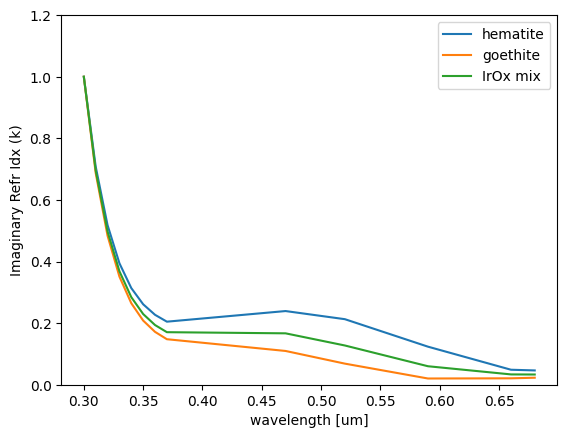

In [17]:
n = 49 # the wvls index in xwvl for the last visible wvl: 780nm
plt.plot(xwvl[10:n], khem[10:n], label="hematite")
plt.plot(xwvl[10:n], kgoe[10:n], label="goethite")
plt.plot(xwvl[10:n], kiox[10:n], label="IrOx mix")
plt.ylim([0,1.2])
plt.xlabel("wavelength [um]")
plt.ylabel("Imaginary Refr Idx (k)")
plt.legend()

 # OPTICAL PROPERTIES

In [18]:
qext, qsca, qasy = nmp.zeros([S,B_mono,Im,Im]), nmp.zeros([S,B_mono,Im,Im]), nmp.zeros([S,B_mono,Im,Im]) #For IMB=0
vext, vsca, vasy = nmp.zeros([S,B_mono,Im,Im]), nmp.zeros([S,B_mono,Im,Im]), nmp.zeros([S,B_mono,Im,Im]) #For IMB=1
wext, wsca, wasy = nmp.zeros([S,B_mono,Im,Im]), nmp.zeros([S,B_mono,Im,Im]), nmp.zeros([S,B_mono,Im,Im]) #For IMB=2
#Altough only IMB=2 will fill all the dimensions (21 bins of 2 IrOx species) all need to have same shape for the netCDF file.

 ## Homogeneous dust physics

In [19]:
vhos = nmp.sum(hvol)
vhem = fvol[0]
vgoe = fvol[1]
#Check the vol % of host+hema+goe is 1
print('vhem:',vhem,' , vgoe:',vgoe)
print( 'vhos + vhem + vgoe: ', vhos+vhem+vgoe )

ddus = dhos*vhos + dhem*vhem + dgoe*vgoe 
#(density of the homogenous mixture by a weight avrg) (weight = vol%)

#Maxwell-Garnett (permitivities and so on):
ehos = (nhos + 1j*khos)**2 #e==permitivity (=CRI^2) (needed for mixing rule)
ehem = (nhem + 1j*khem)**2
egoe = (ngoe + 1j*kgoe)**2

xhem = (ehem - ehos)/(ehem + 2.0*ehos)
xgoe = (egoe - ehos)/(egoe + 2.0*ehos)

ymxg = xhem*vhem + xgoe*vgoe 
emxg = ehos*(1.0 + 2.0*ymxg)/(1.0 - ymxg) 

#Once you have the effective permitivity, back to CRI with the sqrt:
ndus = nmp.sqrt(emxg).real
kdus = nmp.sqrt(emxg).imag
#They are spectral values for each of Scanzas wvl (1200) (Lx)

vhem: 0.0026649265871168254  , vgoe: 0.012003522323463295
vhos + vhem + vgoe:  1.0


 ### Shortwave wavelengths


In [20]:
#All the CRI values for the 1200 wvls
out = nmp.column_stack([xwvl, nhos, khos, nhem, khem, ngoe, kgoe, niox, kiox, ndus, kdus])
nmp.savetxt('shortwave_cris.txt', out, fmt='%11.5e')

 ## Mixture refractive index

In [21]:
def MixCris(INB):
 """
   Retrurns the k and n of dust for different mixtures types using Maxwell-Garnett.

   Varying ING (the input) you select the type of mixure you want:
   IMB=0: Same as IMB=2 but for fixed mass% of hema and goet (from emjkok) (dim:(1200))
   IMB=1: Host + IrOx (dim:(21,0,1200)) (only 1 IrOx specie)
   IMB=2: Host + Hematite + Goethite (dim:(21,21,1200))(2 IrOx species)
 """

 NMX, KMX = nmp.zeros([Im,Im,Lx]), nmp.zeros([Im,Im,Lx])  #Im=21 Grid IrOx mass-fractions (see M3), Lx=1200 wvls

 if INB == 0:
  NMX[:,:,:] = ndus #Takes the previous calculated n and k for the mix (emjkok_nomask)
  KMX[:,:,:] = kdus #Linear arrays of Lx elements (but repeated in the 2 first dims (Im,Im) for consistency with other IMB)
################################################################

 if INB == 1:
  for m3 in nmp.arange(Im):

   M3 = igrd[m3] #just the grid for different cases of IrOx % (0% to 10%, Im(20) steps)
   MH = 1.0 - M3 #the rest is host (therefore from 100% to 90%)

   VH = MH/dhos #vol % with the respect densities
   V3 = M3/diox
   VT = VH + V3
   VH = VH/VT
   V3 = V3/VT

#Again Maxwell-Garnett mixing rule with permitivities (E=CRI^2)
   EHS = (nhos + 1j*khos)**2
   EIX = (niox + 1j*kiox)**2

   XIX = (EIX - EHS)/(EIX + 2.0*EHS)

   YMX = XIX*V3
   EMX = EHS*(1.0 + 2.0*YMX)/(1.0 - YMX)

#Result for IMB=1 (first dim is just the index (0,20)) (but each represents a IrOx mass % (see M3))
   NMX[m3,:,:] = nmp.sqrt(EMX).real
   KMX[m3,:,:] = nmp.sqrt(EMX).imag
################################################################

 if INB == 2:
  for m1 in nmp.arange(Im):
   for m2 in nmp.arange(Im):

    M1 = igrd[m1] #Same but now both hema and goet cases (0% to 10%, Im(20) steps)
    M2 = igrd[m2] #Thats why now we need the 3 dim array (21,21,1200)
    MH = 1.0 - M1 - M2

    VH = MH/dhos #Same as before: vol %
    V1 = M1/dhem
    V2 = M2/dgoe
    VT = VH + V1 + V2
    VH = VH/VT
    V1 = V1/VT
    V2 = V2/VT

#Max-Garn multicomponent with a common host (small mod, see notes)
    EHS = (nhos + 1j*khos)**2
    EHM = (nhem + 1j*khem)**2
    EGT = (ngoe + 1j*kgoe)**2

    XHM = (EHM - EHS)/(EHM + 2.0*EHS)
    XGT = (EGT - EHS)/(EGT + 2.0*EHS)

    YMX = XHM*V1 + XGT*V2
    EMX = EHS*(1.0 + 2.0*YMX)/(1.0 - YMX)

#Result for IMB=2 (first and sec dim are just the index (0,20)) (but each represents a hema/goet mass % (see M1,M2))
    NMX[m1,m2,:] = nmp.sqrt(EMX).real
    KMX[m1,m2,:] = nmp.sqrt(EMX).imag

 return NMX, KMX

## DB19 esxtension of ks to the UV

In [22]:
vhos = nmp.sum(hvol)
vhem = fvol[0]
vgoe = fvol[1]
#Check the vol % of host+hema+goe is 1
print('vhem:',vhem,' , vgoe:',vgoe)
print( 'vhos + vhem + vgoe: ', vhos+vhem+vgoe )

ddus = dhos*vhos + dhem*vhem + dgoe*vgoe 
#(density of the homogenous mixture by a weight avrg) (weight = vol%)

#Maxwell-Garnett (permitivities and so on):
ehos = (nhos + 1j*khos)**2 #e==permitivity (=CRI^2) (needed for mixing rule)
ehem = (nhem + 1j*khem)**2
egoe = (ngoe + 1j*kgoe)**2

xhem = (ehem - ehos)/(ehem + 2.0*ehos)
xgoe = (egoe - ehos)/(egoe + 2.0*ehos)

ymxg = xhem*vhem + xgoe*vgoe 
emxg = ehos*(1.0 + 2.0*ymxg)/(1.0 - ymxg) 

#Once you have the effective permitivity, back to CRI with the sqrt:
ndus = nmp.sqrt(emxg).real
kdus = nmp.sqrt(emxg).imag
#They are spectral values for each of Scanzas wvl (1200) (Lx)

vhem: 0.0026649265871168254  , vgoe: 0.012003522323463295
vhos + vhem + vgoe:  1.0


In [23]:
MIX = nmp.zeros([18,Lx])
for j in range(18):
    M1 = bmas[4,j]*0.01
    M2 = bmas[5,j]*0.01
    M3 = M1 + M2
    MH = 1.0 - M3
    VH, V3 = MH/dhos, M3/diox
    VH, V3 = VH/(VH+V3), V3/(VH+V3)
    EH = (nhos + 1j*khos)**2
    E3 = (niox + 1j*kiox)**2
    X3 = (E3-EH)/(E3+2.0*EH)
    EMX = EH*(1.0+2.0*X3*V3)/(1.0-X3*V3)
    MIX[j,:] = nmp.sqrt(EMX).imag

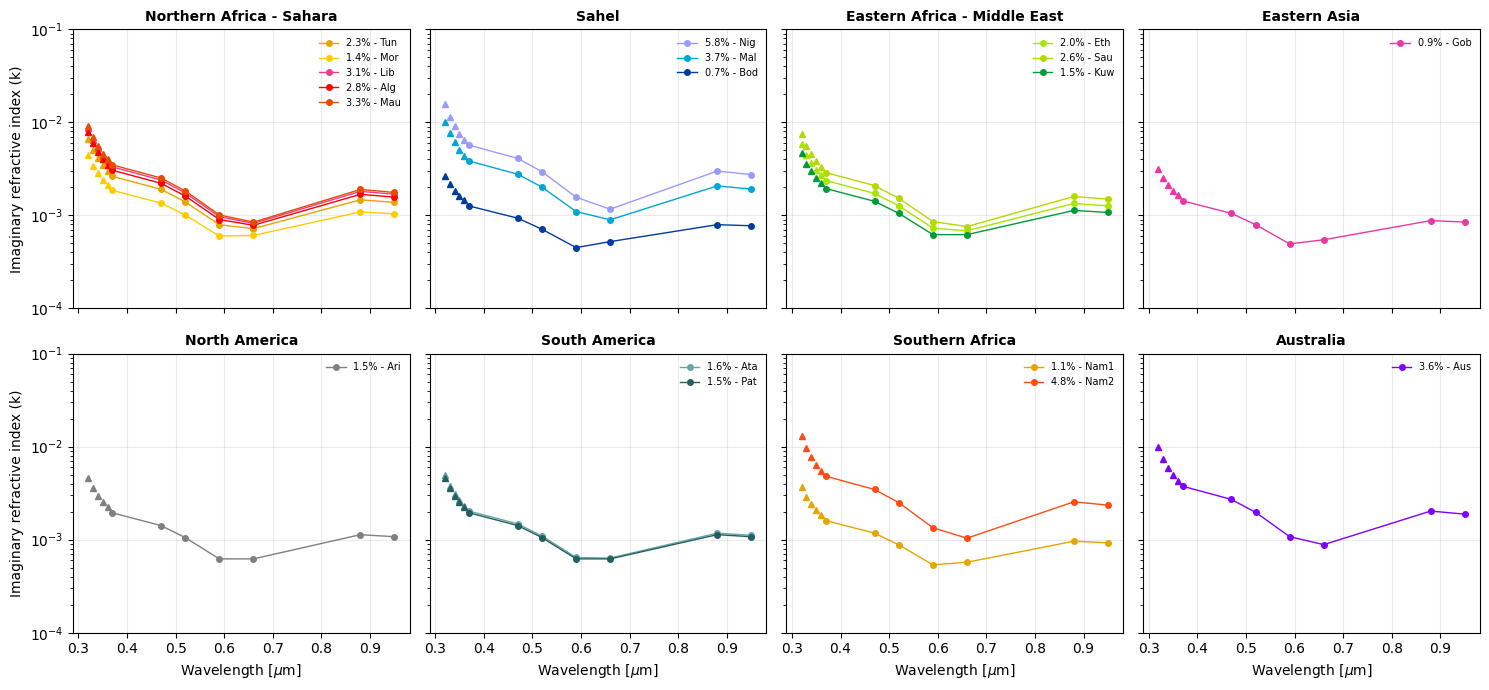

In [24]:

# --- PLOT

groups = [
    ('Northern Africa - Sahara', [0,1,2,3,4], ['#e6a500','#ffcc00','#e83e8c','#ff0000','#e64b00']),
    ('Sahel', [5,6,7], ['#9b9bff','#00a6d6','#003b9e']),
    ('Eastern Africa - Middle East', [8,9,10], ['#a6e600','#b5d900','#009b39']),
    ('Eastern Asia', [11], ['#ed35a5']),
    ('North America', [12], ['#808080']),
    ('South America', [13,14], ['#66a6a6','#245f60']),
    ('Southern Africa', [15,16], ['#e6a500','#ff4b16']),
    ('Australia', [17], ['#8000ff'])
]

fig, axs = plt.subplots(2,4,figsize=(15,7),sharex=True,sharey=True)

uv = nmp.arange(12,17) # 0.32-0.36 um in xwvl
db = xtob

for ax,(region,ids,cols) in zip(axs.flat,groups):
    for j,c in zip(ids,cols):
        ax.plot(xwvl[db],MIX[j,db],color=c,marker='o',ls='-',ms=4,lw=1,label=f'{bmas[4,j]+bmas[5,j]:.1f}% - {["Tun","Mor","Lib","Alg","Mau","Nig","Mal","Bod","Eth","Sau","Kuw","Gob","Ari","Ata","Pat","Nam1","Nam2","Aus"][j]}')
        ax.plot(xwvl[uv],MIX[j,uv],color=c,marker='^',ls='none',ms=5)

    ax.set_title(region,fontsize=10,fontweight='bold')
    ax.set_yscale('log')
    ax.set_ylim(1e-4,1e-1)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=7,loc='best',frameon=False)

for ax in axs[1,:]:
    ax.set_xlabel('Wavelength [$\\mu$m]')
for ax in axs[:,0]:
    ax.set_ylabel('Imaginary refractive index (k)')

fig.tight_layout()
plt.show()


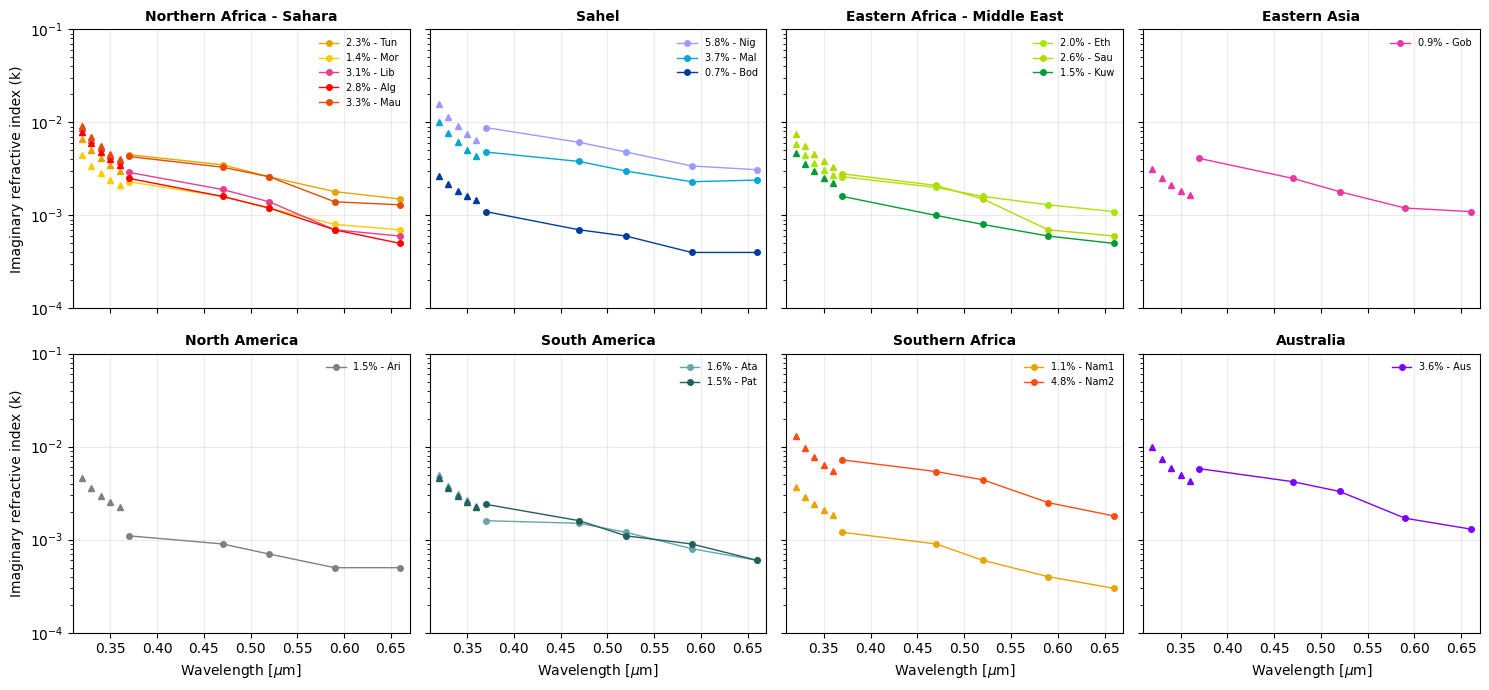

In [26]:

# --- PLOT

samples = ['Tun','Mor','Lib','Alg','Mau','Nig','Mal','Bod','Eth','Sau','Kuw','Gob','Ari','Ata','Pat','Nam1','Nam2','Aus']

groups = [
    ('Northern Africa - Sahara', [0,1,2,3,4], ['#e6a500','#ffcc00','#e83e8c','#ff0000','#e64b00']),
    ('Sahel', [5,6,7], ['#9b9bff','#00a6d6','#003b9e']),
    ('Eastern Africa - Middle East', [8,9,10], ['#a6e600','#b5d900','#009b39']),
    ('Eastern Asia', [11], ['#ed35a5']),
    ('North America', [12], ['#808080']),
    ('South America', [13,14], ['#66a6a6','#245f60']),
    ('Southern Africa', [15,16], ['#e6a500','#ff4b16']),
    ('Australia', [17], ['#8000ff'])
]

fig, axs = plt.subplots(2,4,figsize=(15,7),sharex=True,sharey=True)

uv = nmp.arange(12,17) # 0.32-0.36 um
db = nmp.array([0,1,2,3,4]) # 0.37-0.66 um in biri

for ax,(region,ids,cols) in zip(axs.flat,groups):
    for j,c in zip(ids,cols):
        ax.plot(xwvl[uv],MIX[j,uv],color=c,marker='^',ls='none',ms=5)
        ax.plot(bwvl[db],biri[db,j],color=c,marker='o',ls='-',ms=4,lw=1,label=f'{bmas[4,j]+bmas[5,j]:.1f}% - {samples[j]}')

    ax.set_title(region,fontsize=10,fontweight='bold')
    ax.set_yscale('log')
    ax.set_ylim(1e-4,1e-1)
    ax.set_xlim(0.31,0.67)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=7,loc='best',frameon=False)

for ax in axs[1,:]:
    ax.set_xlabel('Wavelength [$\\mu$m]')
for ax in axs[:,0]:
    ax.set_ylabel('Imaginary refractive index (k)')

fig.tight_layout()
plt.show()


UV effective k (rows: samples, columns: wavelengths)
Wavelengths [nm]: [320. 330. 340. 350. 360.]
[[0.00666 0.00505 0.0041  0.00346 0.00301]
 [0.00441 0.00342 0.00282 0.00242 0.00213]
 [0.00868 0.00652 0.00525 0.00439 0.0038 ]
 [0.00792 0.00597 0.00482 0.00404 0.0035 ]
 [0.00919 0.00689 0.00553 0.00462 0.004  ]
 [0.01562 0.01155 0.00918 0.00758 0.00651]
 [0.01021 0.00762 0.00611 0.00509 0.00439]
 [0.00267 0.00215 0.00184 0.00162 0.00145]
 [0.00591 0.0045  0.00367 0.00311 0.00272]
 [0.00742 0.0056  0.00453 0.0038  0.00331]
 [0.00466 0.0036  0.00297 0.00253 0.00223]
 [0.00317 0.00251 0.00212 0.00185 0.00165]
 [0.00466 0.0036  0.00297 0.00253 0.00223]
 [0.00491 0.00378 0.00311 0.00265 0.00233]
 [0.00466 0.0036  0.00297 0.00253 0.00223]
 [0.00366 0.00287 0.0024  0.00207 0.00184]
 [0.01303 0.00967 0.00771 0.00639 0.0055 ]
 [0.00995 0.00744 0.00597 0.00497 0.0043 ]]


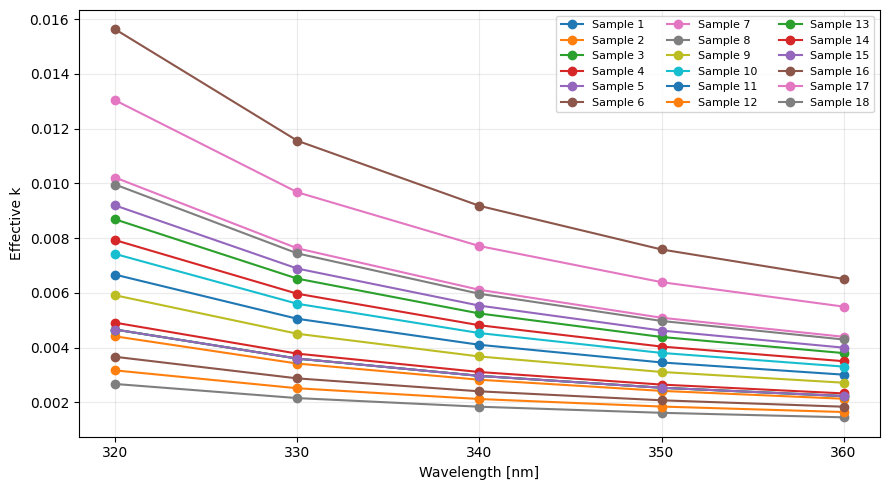

In [25]:
uv_wvl = nmp.array([0.320,0.330,0.340,0.350,0.360])
uv_idx = nmp.array([nmp.argmin(nmp.abs(xwvl-w)) for w in uv_wvl])
uv_k = MIX[:,uv_idx]

print('UV effective k (rows: samples, columns: wavelengths)')
print('Wavelengths [nm]:',uv_wvl*1000)
print(nmp.round(uv_k,5))

# %%
fig, ax = plt.subplots(figsize=(9,5))
for j in range(18):
    ax.plot(uv_wvl*1000,uv_k[j,:],marker='o',label=f'Sample {j+1}')
ax.set(xlabel='Wavelength [nm]',ylabel='Effective k',xticks=uv_wvl*1000)
ax.grid(alpha=0.25)
ax.legend(ncol=3,fontsize=8)
plt.tight_layout()
plt.show()